# KAN on Pd-catalyzed direct arylation with continuous conditions

**Source.** Shields, Stevens, Li, Parasram, Damani, Martinez Alvarado, Janey, Adams, Doyle,
*Nature* **2021**, *590*, 89-96 (DOI 10.1038/s41586-021-03213-y), the dataset used to benchmark
Bayesian reaction optimization. Files from the `edbo` package (`direct_arylation/`): the
experiment index and the DFT descriptor tables for ligands (Boltzmann-averaged), bases and
solvents.

**Reaction.** Pd-catalyzed C-H arylation of an imidazole with an aryl bromide over a full
factorial of 12 phosphine ligands, 4 carboxylate bases (KOAc, KOPiv, CsOAc, CsOPiv),
4 solvents (DMAc, BuCN, BuOAc, *p*-xylene), 3 concentrations (0.057, 0.100, 0.153 M) and
3 temperatures (90, 105, 120 °C): 1728 reactions.

**Why it is a useful test.** This is the first dataset in the series whose variables include
reaction conditions rather than only molecule labels. Temperature and concentration are physical
quantities, so their effect can be held against a rate law, although each was sampled at only
three levels, which is a table of three means rather than a curve. The C-H activation step is a
concerted metalation-deprotonation in which the carboxylate base sits in the transition state, so
base identity (pivalate against acetate, cesium against potassium) is expected to matter more
than its size descriptors alone would suggest.

**Descriptors used here.** Temperature and concentration as given; six Boltzmann-averaged ligand
descriptors (percent buried volume at P, HOMO, LUMO, hardness, dipole, molar volume); four for the
base (dipole, molar volume, HOMO, LUMO) and four for the solvent (dipole, molar volume, HOMO,
LUMO). With four bases and four solvents, three independent effects each is the ceiling.

**Target.** Yield in percent, regression. Success for the threshold rules: above 20 % yield.

A caution that applies to the temperature reading below: these are yields after a fixed time, not
rate constants. A yield that has not saturated is roughly proportional to rate, so an Arrhenius
plot of the three temperature means gives an apparent barrier, not a measured activation energy.

## What this notebook does

Every dataset notebook in this series runs the same pipeline from `pycse.sklearn.kan_interpret`,
so the results are comparable across chemistries:

1. **Models on identical folds.** A linear baseline, random forest, gradient boosting and a KAN
   scored by 5x3 repeated cross-validation with the scaler refit inside each fold, and a paired
   Wilcoxon test of the KAN against the best other model.
2. **Single-descriptor thresholds.** Class-balanced stumps scored by balanced accuracy, with the
   majority baseline, so a "rule" that only predicts the majority class scores 0.5.
3. **Partial effects with fold envelopes.** One-descriptor response curves of the KAN in the
   descriptor's own units, with the linear baseline on the same grid and the envelope of five
   refits. A shape that changes from fold to fold is not a finding.
4. **A check against the known chemistry.** What the source paper established, or (for the
   synthetic benchmark) the generating equations, overlaid on what the pipeline recovered.

No emoji, no claims from a single fit.


In [1]:
import os

os.environ["JAX_PLATFORM_NAME"] = "cpu"
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    RandomForestClassifier,
    GradientBoostingClassifier,
)
from sklearn.metrics import r2_score, mean_absolute_error, roc_auc_score, accuracy_score

from pycse.sklearn.kan import KAN
from pycse.sklearn.kan_interpret import (
    classify_shape,
    cv_compare,
    partial_effects,
    partial_effects_cv,
    plot_fold_scores,
    plot_partial_effect,
    sensitivity,
    threshold_rules,
)
from pycse.sklearn._plotstyle import (
    INK_2,
    MUTED,
    BASELINE,
    SURFACE,
    SERIES,
    PX,
    style_axes,
    finish_axes,
)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Record the environment: KAN fits move slightly between jax/XLA builds.
import importlib.metadata as _md

print(
    "Versions:",
    ", ".join(
        f"{p} {_md.version(p)}" for p in ("pycse", "jax", "optax", "numpy", "scikit-learn", "scipy")
    ),
)


Versions: pycse 2.13.0, jax 0.12.0.1, optax 0.2.8, numpy 2.5.4, scikit-learn 1.9.1, scipy 1.18.1


## 1. Load the experiment index and join the component descriptors

The join keys are the SMILES strings in the index, which match the descriptor tables exactly.


In [2]:
BASE = "https://raw.githubusercontent.com/b-shields/edbo/master/examples/DOE/data/direct_arylation/"
idx = pd.read_csv(BASE + "experiment_index.csv")
lig = pd.read_csv(BASE + "ligand-boltzmann_dft.csv")
bas = pd.read_csv(BASE + "base_dft.csv")
sol = pd.read_csv(BASE + "solvent_dft.csv")

LIG = {
    "ligand_pct_Vbur_P": "ligand_atom1_%VBur_Boltz", "ligand_E_HOMO": "ligand_homo_energy_Boltz",
    "ligand_E_LUMO": "ligand_lumo_energy_Boltz", "ligand_hardness": "ligand_hardness_Boltz",
    "ligand_dipole": "ligand_dipole_Boltz", "ligand_molar_volume": "ligand_molar_volume_Boltz",
}  # fmt: skip
BAS = {"base_dipole": "base_dipole", "base_molar_volume": "base_molar_volume", "base_E_HOMO": "base_homo_energy", "base_E_LUMO": "base_lumo_energy"}
SOL = {"solvent_dipole": "solvent_dipole", "solvent_molar_volume": "solvent_molar_volume", "solvent_E_HOMO": "solvent_homo_energy", "solvent_E_LUMO": "solvent_lumo_energy"}

df = idx.merge(lig[["ligand_SMILES", "ligand_file_name", *LIG.values()]].rename(columns={"ligand_SMILES": "Ligand_SMILES"}), on="Ligand_SMILES", how="left")
df = df.merge(bas[["base_SMILES", "base_file_name", *BAS.values()]].rename(columns={"base_SMILES": "Base_SMILES"}), on="Base_SMILES", how="left")
df = df.merge(sol[["solvent_SMILES", "solvent_file_name", *SOL.values()]].rename(columns={"solvent_SMILES": "Solvent_SMILES"}), on="Solvent_SMILES", how="left")
assert df[list(LIG.values())].notna().all().all() and len(df) == len(idx)
df["ligand_pct_Vbur_P"] = 100.0 * df["ligand_atom1_%VBur_Boltz"]  # fraction to percent

X_df = pd.DataFrame({"temperature_C": df["Temp_C"].astype(float), "concentration_M": df["Concentration"].astype(float)})
for new, old in {**LIG, **BAS, **SOL}.items():
    if new != "ligand_pct_Vbur_P":
        X_df[new] = df[old].astype(float)
    else:
        X_df[new] = df[new]
COMPONENT = {"temperature_C": "conditions", "concentration_M": "conditions"}
COMPONENT.update({k: "ligand" for k in LIG})
COMPONENT.update({k: "base" for k in BAS})
COMPONENT.update({k: "solvent" for k in SOL})
y = df["yield"].to_numpy(dtype=float)
TASK = "regression"
Y_LABEL = "yield (%)"
SUCCESS = (y > 20.0).astype(int)
SUCCESS_RULE = "yield above 20 %"
print(f"{len(df)} reactions: {df.ligand_file_name.nunique()} ligands x {df.base_file_name.nunique()} bases x {df.solvent_file_name.nunique()} solvents x {df.Concentration.nunique()} concentrations x {df.Temp_C.nunique()} temperatures")
for comp in ["ligand_file_name", "base_file_name", "solvent_file_name", "Temp_C", "Concentration"]:
    print(df.groupby(comp)["yield"].mean().round(1).sort_values(ascending=False).to_dict())


1728 reactions: 12 ligands x 4 bases x 4 solvents x 3 concentrations x 3 temperatures
{'X-Phos': 52.8, 'CgMe-PPh': 50.2, 'P(fur)3': 27.3, 'BrettPhos': 25.6, 'GorlosPhos': 19.2, 'JackiePhos': 17.7, 'PPh3': 16.6, 'tBPh-CPhos': 16.5, 'PCy3': 3.8, 'PPh2Me': 2.0, 'PPhtBu2': 0.4, 'PPhMe2': 0.3}
{'CsOAc': 22.8, 'KOPiv': 21.5, 'CsOPiv': 17.2, 'KOAc': 16.0}
{'DMAc': 30.4, 'BuCN': 20.6, 'p-Xylene': 13.5, 'BuOAc': 13.0}
{120: 24.1, 105: 20.3, 90: 13.7}
{0.153: 20.5, 0.1: 19.6, 0.057: 18.1}


1728 reactions, 16 descriptors. Target: yield (%) (regression).
Success for the threshold rules: yield above 20 % (34% of reactions).


,Component,Distinct,Min,Max
temperature_C,conditions,3,90.000,120.000
concentration_M,conditions,3,0.057,0.153
ligand_pct_Vbur_P,ligand,12,64.261,84.701
ligand_E_HOMO,ligand,12,-0.224,-0.189
ligand_E_LUMO,ligand,12,-0.051,0.054
ligand_hardness,ligand,12,0.082,0.128
ligand_dipole,ligand,12,0.659,5.515
ligand_molar_volume,ligand,12,1401.560,5672.572
base_dipole,base,4,7.169,11.011
base_molar_volume,base,4,406.010,1542.838


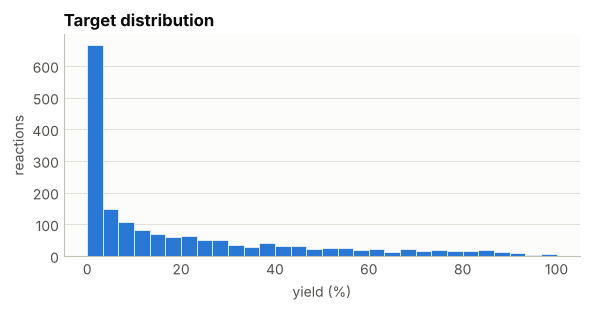

In [3]:
feature_names = list(X_df.columns)
X = X_df.to_numpy(dtype=float)
y = np.asarray(y, dtype=float)
SUCCESS = np.asarray(SUCCESS, dtype=int)
n_features = len(feature_names)
COMPONENTS = list(dict.fromkeys(COMPONENT[f] for f in feature_names))
COMP_COLOR = {c: SERIES[k % len(SERIES)] for k, c in enumerate(COMPONENTS)}

desc = pd.DataFrame(
    {
        "Component": [COMPONENT[f] for f in feature_names],
        "Distinct": X_df.nunique().values,
        "Min": X_df.min().values,
        "Max": X_df.max().values,
    },
    index=feature_names,
)
print(f"{len(X)} reactions, {n_features} descriptors. Target: {Y_LABEL} ({TASK}).")
print(f"Success for the threshold rules: {SUCCESS_RULE} ({SUCCESS.mean():.0%} of reactions).")
display(desc.round(3))

fig, ax = plt.subplots(figsize=(6, 3.2))
style_axes(ax)
if TASK == "regression":
    ax.hist(y, bins=30, color=SERIES[0], edgecolor=SURFACE, linewidth=0.5)
    finish_axes(ax, "Target distribution", Y_LABEL, "reactions")
else:
    vals, counts = np.unique(y, return_counts=True)
    ax.bar(vals, counts, width=0.6, color=[MUTED, SERIES[0]], linewidth=0)
    ax.set_xticks(vals)
    ax.set_xticklabels([f"{int(v)} ({c})" for v, c in zip(vals, counts)])
    finish_axes(ax, "Class balance", Y_LABEL, "reactions")
plt.tight_layout()
plt.show()


## 2. Models on identical folds

The four models see exactly the same 15 folds (5 splits x 3 repeats, scaler refit per fold).
The paired comparison asks a narrow question: on the same held-out reactions, is the KAN better
than the best of the other models, and how often?


Model                  r2               other
MLR                    0.289 ± 0.043   16.646 ± 0.765 (mae)
Random Forest          0.868 ± 0.021   4.907 ± 0.360 (mae)
Gradient Boosting      0.894 ± 0.018   4.846 ± 0.284 (mae)
KAN                    0.865 ± 0.018   5.886 ± 0.354 (mae)
KAN vs Gradient Boosting, paired over 15 folds: Δr2 = -0.0292 ± 0.0131, KAN better in 0/15, Wilcoxon p = 6.1e-05
(144 s)


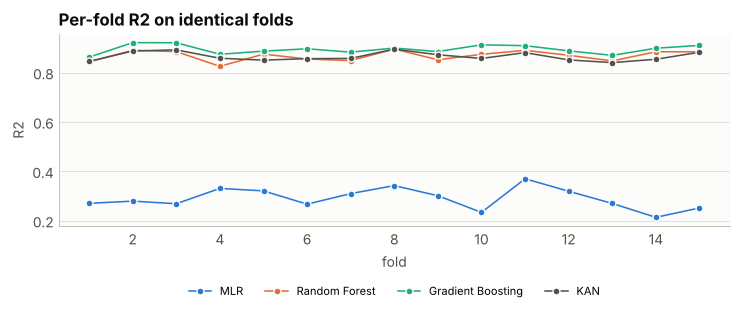

In [4]:
# One hidden layer; width 8 and 5 knots on datasets of 1000 reactions or more,
# 4 and 3 below that, so the spline count stays in proportion to the data.
WIDE = len(X) >= 1000
KAN_LAYERS = (n_features, 8 if WIDE else 4, 1)
KAN_GRID = 5 if WIDE else 3
KAN_MAXITER = 300
CV_SPLITS, CV_REPEATS, CV_SEED = 5, 3, 42


def make_kan():
    return KAN(layers=KAN_LAYERS, grid_size=KAN_GRID, spline_order=3)


def make_models():
    """Fresh models; the ensembles use the settings of the first two chemistry notebooks."""
    if TASK == "regression":
        return {
            "MLR": LinearRegression(),
            "Random Forest": RandomForestRegressor(
                n_estimators=300, max_depth=12, min_samples_split=5, min_samples_leaf=2,
                random_state=42, n_jobs=-1,
            ),  # fmt: skip
            "Gradient Boosting": GradientBoostingRegressor(
                n_estimators=300, learning_rate=0.1, max_depth=4, min_samples_split=5,
                min_samples_leaf=3, subsample=0.8, random_state=42,
            ),  # fmt: skip
            "KAN": make_kan(),
        }
    return {
        "Logistic": LogisticRegression(max_iter=2000),
        "Random Forest": RandomForestClassifier(
            n_estimators=300, max_depth=12, min_samples_split=5, min_samples_leaf=2,
            random_state=42, n_jobs=-1,
        ),  # fmt: skip
        "Gradient Boosting": GradientBoostingClassifier(
            n_estimators=300, learning_rate=0.1, max_depth=4, min_samples_split=5,
            min_samples_leaf=3, subsample=0.8, random_state=42,
        ),  # fmt: skip
        "KAN": make_kan(),
    }


BASELINE_NAME = "MLR" if TASK == "regression" else "Logistic"

t0 = time.time()
cv_result = cv_compare(
    make_models(),
    X,
    y,
    task=TASK,
    n_splits=CV_SPLITS,
    n_repeats=CV_REPEATS,
    random_state=CV_SEED,
    fit_kwargs={"KAN": {"maxiter": KAN_MAXITER}},
    verbose=False,
)
print(cv_result)
print(f"({time.time() - t0:.0f} s)")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
plot_fold_scores(ax, cv_result)
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.25))
plt.tight_layout()
plt.show()


Held-out split: 1382 train / 346 test


,Test R2,Test MAE
Model,,
MLR,0.270,16.549
Random Forest,0.841,5.155
Gradient Boosting,0.859,5.149
KAN,0.844,6.158


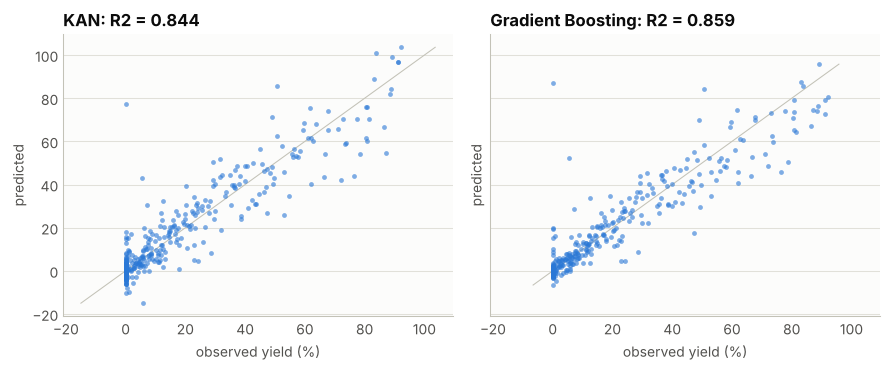

In [5]:
# One held-out split for the models the rest of the notebook interprets.
strat = y.astype(int) if TASK == "classification" else None
idx_tr, idx_te = train_test_split(np.arange(len(X)), test_size=0.2, random_state=42, stratify=strat)
scaler = StandardScaler().fit(X[idx_tr])
X_tr, X_te = scaler.transform(X[idx_tr]), scaler.transform(X[idx_te])
y_tr, y_te = y[idx_tr], y[idx_te]

fitted, rows = {}, []
for name, model in make_models().items():
    if name == "KAN":
        model.fit(X_tr, y_tr, maxiter=KAN_MAXITER)
    else:
        model.fit(X_tr, y_tr.astype(int) if TASK == "classification" else y_tr)
    fitted[name] = model
    if TASK == "regression":
        p = model.predict(X_te)
        rows.append({"Model": name, "Test R2": r2_score(y_te, p), "Test MAE": mean_absolute_error(y_te, p)})
    else:
        p = model.predict_proba(X_te)[:, 1] if hasattr(model, "predict_proba") else np.clip(model.predict(X_te), 0, 1)
        rows.append({"Model": name, "Test AUC": roc_auc_score(y_te, p), "Test accuracy": accuracy_score(y_te, (p > 0.5).astype(int))})
kan, baseline = fitted["KAN"], fitted[BASELINE_NAME]


def model_means(labels, model=None):
    """Observed and predicted mean target per group, over the training reactions.

    A partial effect fixes the other descriptors at their mean, which is not a real
    compound; to compare a model with observed group means, average its predictions
    over the reactions that were actually run.
    """
    model = model or kan
    pred = np.ravel(model.predict(X_tr))
    lab = np.asarray(labels)[idx_tr]
    return (
        pd.DataFrame({"label": lab, "observed": y[idx_tr], "predicted": pred})
        .groupby("label")
        .agg(observed=("observed", "mean"), predicted=("predicted", "mean"), n=("observed", "size"))
    )
headline = pd.DataFrame(rows).set_index("Model")
print(f"Held-out split: {len(idx_tr)} train / {len(idx_te)} test")
display(headline.round(3))

# The KAN against the best other model on the held-out reactions
metric = "Test R2" if TASK == "regression" else "Test AUC"
best_other = headline.drop("KAN")[metric].idxmax()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharex=True, sharey=True)
for ax, name in zip(axes, ["KAN", best_other]):
    style_axes(ax)
    m = fitted[name]
    if TASK == "regression":
        p = m.predict(X_te)
        lim = [min(y_te.min(), p.min()), max(y_te.max(), p.max())]
        ax.plot(lim, lim, color=BASELINE, linewidth=PX, zorder=1)
        ax.scatter(y_te, p, s=12, color=SERIES[0], alpha=0.6, linewidths=0, zorder=2)
        finish_axes(ax, f"{name}: R2 = {headline.loc[name, metric]:.3f}", f"observed {Y_LABEL}", "predicted")
    else:
        p = m.predict_proba(X_te)[:, 1] if hasattr(m, "predict_proba") else np.clip(m.predict(X_te), 0, 1)
        bins = np.linspace(0, 1, 21)
        ax.hist(p[y_te == 0], bins=bins, color=MUTED, alpha=0.7, label="observed 0", linewidth=0)
        ax.hist(p[y_te == 1], bins=bins, color=SERIES[0], alpha=0.7, label="observed 1", linewidth=0)
        ax.legend(frameon=False, fontsize=8)
        finish_axes(ax, f"{name}: AUC = {headline.loc[name, metric]:.3f}", "predicted probability", "reactions")
plt.tight_layout()
plt.show()


## 3. Single-descriptor thresholds

The Doyle and Sigman groups look for reactivity cliffs with one cut on one descriptor. The same
search here: a depth-1 tree with balanced class weights on each descriptor, scored on the held-out
reactions by balanced accuracy. A descriptor with no information scores 0.5 whatever the class
balance.


Majority-class accuracy on the test reactions: 0.653
Balanced-accuracy baseline for guessing: 0.500


,Feature,Threshold,Balanced_Acc,Accuracy,Precision,Recall
0,ligand_pct_Vbur_P,82.967,0.690,0.743,0.667,0.517
1,ligand_E_LUMO,-0.014,0.651,0.590,0.451,0.850
2,ligand_molar_volume,2381.551,0.649,0.569,0.441,0.908
3,ligand_hardness,0.103,0.627,0.517,0.417,0.983
4,base_E_LUMO,-0.048,0.609,0.535,0.416,0.850
5,base_dipole,7.471,0.609,0.535,0.416,0.850
6,solvent_dipole,2.696,0.600,0.590,0.437,0.633
7,solvent_molar_volume,974.462,0.600,0.590,0.437,0.633
8,solvent_E_LUMO,0.025,0.600,0.590,0.437,0.633
9,ligand_dipole,1.137,0.582,0.673,0.557,0.283


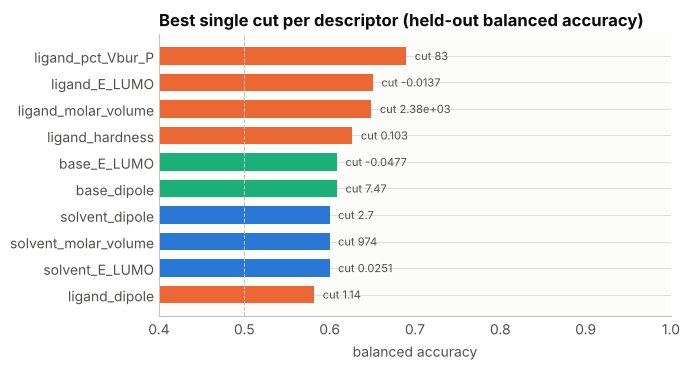

In [6]:
rules = threshold_rules(X[idx_tr], SUCCESS[idx_tr], feature_names, X[idx_te], SUCCESS[idx_te])
print(f"Majority-class accuracy on the test reactions: {rules.attrs['majority_accuracy']:.3f}")
print("Balanced-accuracy baseline for guessing: 0.500")
display(rules.head(10).round(3))

top = rules.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 3.8))
style_axes(ax)
ax.barh(top.Feature, top.Balanced_Acc, color=[COMP_COLOR[COMPONENT[f]] for f in top.Feature], height=0.65, linewidth=0)
ax.axvline(0.5, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_xlim(0.4, 1.0)
for yk, (f, b, t) in enumerate(zip(top.Feature, top.Balanced_Acc, top.Threshold)):
    ax.text(b + 0.01, yk, f"cut {t:.3g}", va="center", fontsize=8, color=INK_2)
finish_axes(ax, "Best single cut per descriptor (held-out balanced accuracy)", "balanced accuracy", "")
plt.tight_layout()
plt.show()


## 4. Partial effects with fold envelopes

Sensitivity ranks the descriptors by how much the KAN prediction moves per standardized unit,
averaged over the training reactions. The top descriptors get a response curve in their own units
(the other descriptors at their mean), the linear baseline on the same grid, and the envelope of
five refits on disjoint folds. The support strip along the bottom shows where the data are.


,Feature,Component,Sensitivity
0,ligand_pct_Vbur_P,ligand,45.6789
1,ligand_dipole,ligand,45.0056
2,ligand_E_LUMO,ligand,44.3363
3,ligand_molar_volume,ligand,38.8057
4,ligand_E_HOMO,ligand,30.4467
5,solvent_E_HOMO,solvent,22.7694
6,ligand_hardness,ligand,22.1081
7,solvent_molar_volume,solvent,15.0036
8,solvent_E_LUMO,solvent,13.7140
9,base_E_LUMO,base,12.5611


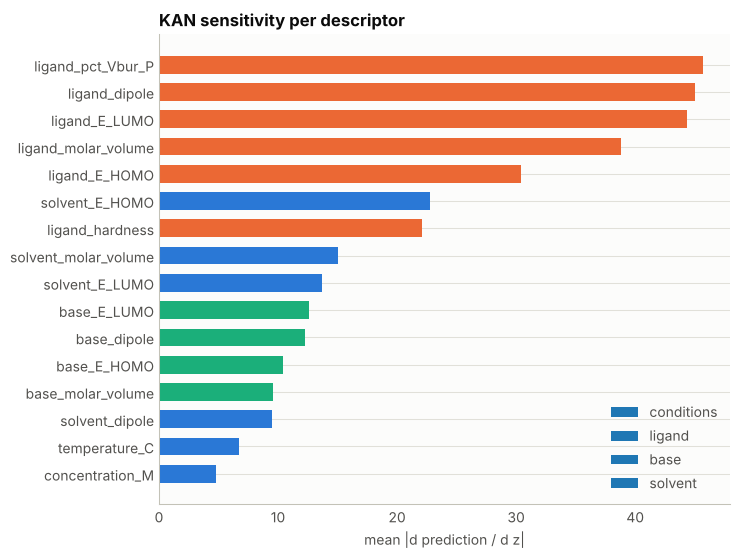

6 descriptors with at least 5 distinct values; 10 with fewer, shown as levels below.


fold envelopes: 28 s


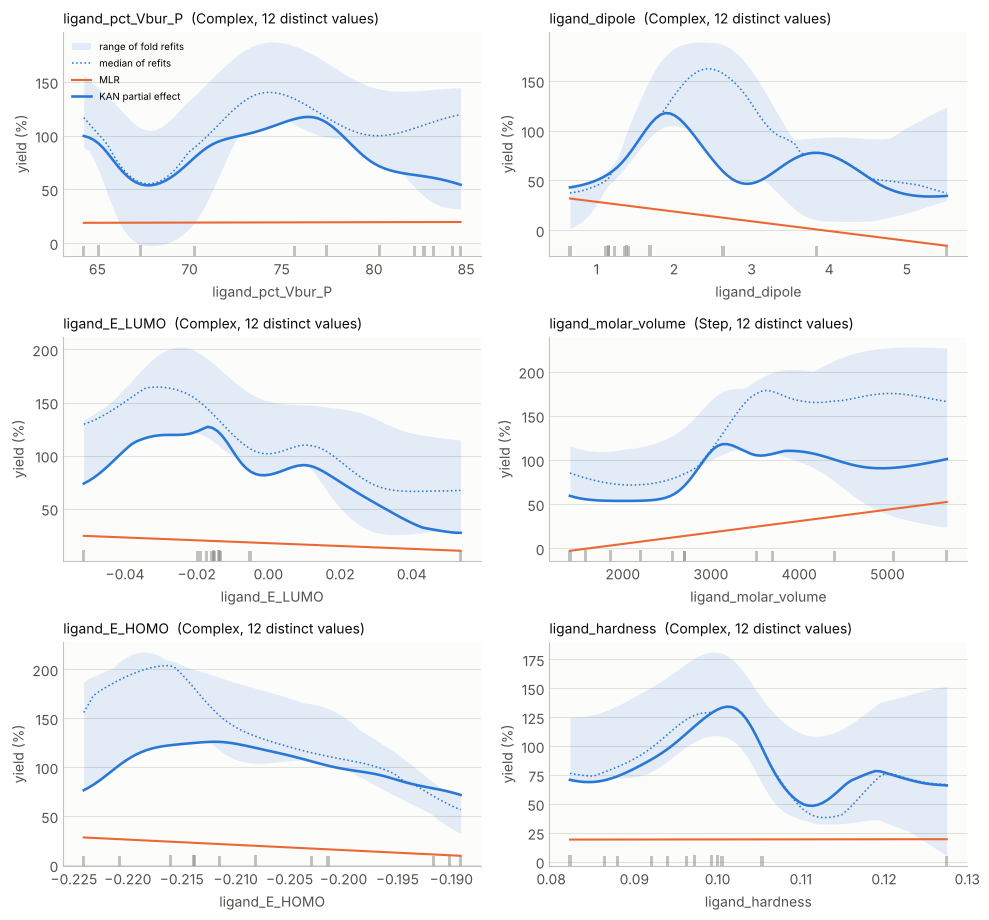

In [7]:
sens = sensitivity(kan, X_tr, task=TASK)
sens_df = pd.DataFrame(
    {"Feature": feature_names, "Component": [COMPONENT[f] for f in feature_names], "Sensitivity": sens}
).sort_values("Sensitivity", ascending=False).reset_index(drop=True)
display(sens_df.round(4))

fig, ax = plt.subplots(figsize=(7.5, 0.28 * n_features + 1.2))
style_axes(ax)
sd = sens_df.iloc[::-1]
ax.barh(sd.Feature, sd.Sensitivity, color=[COMP_COLOR[c] for c in sd.Component], height=0.65, linewidth=0)
for c in COMPONENTS:
    ax.barh([], [], color=COMP_COLOR[c], label=c)
ax.legend(frameon=False, fontsize=8, loc="lower right")
finish_axes(ax, "KAN sensitivity per descriptor", "mean |d prediction / d z|", "")
plt.tight_layout()
plt.show()

# A response curve needs values to interpolate between. Descriptors with fewer
# than five distinct values are handled as levels in the next cell instead.
MIN_LEVELS = 5
rich = [f for f in feature_names if X_df[f].nunique() >= MIN_LEVELS]
few = [f for f in feature_names if f not in rich]
top_features = sens_df[sens_df.Feature.isin(rich)].Feature.head(8).tolist()
TOP_K = len(top_features)
print(f"{len(rich)} descriptors with at least {MIN_LEVELS} distinct values; {len(few)} with fewer, shown as levels below.")
effects = partial_effects(
    kan, X[idx_tr], feature_names, top_features, scaler=scaler, task=TASK,
    extra_models={BASELINE_NAME: baseline},
)  # fmt: skip
t0 = time.time()
effects = partial_effects_cv(
    make_kan, X, y, feature_names, top_features, task=TASK, n_splits=5, random_state=42,
    fit_kwargs={"maxiter": KAN_MAXITER}, effects=effects, verbose=False,
)  # fmt: skip
print(f"fold envelopes: {time.time() - t0:.0f} s")

ncol = 2
nrow = int(np.ceil(TOP_K / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(10, 3.1 * nrow))
for ax, f in zip(np.ravel(axes), top_features):
    plot_partial_effect(ax, effects[f], ylabel=Y_LABEL)
    ax.set_title(f"{f}  ({effects[f].shape(scale=y.std() if TASK == 'regression' else 1.0)[0]}, {effects[f].n_unique} distinct values)", loc="left", fontsize=10)
for ax in np.ravel(axes)[TOP_K:]:
    ax.axis("off")
for ax in np.ravel(axes)[1:TOP_K]:  # one legend is enough
    if ax.get_legend():
        ax.get_legend().remove()
np.ravel(axes)[0].legend(frameon=False, fontsize=7, loc="best")
plt.tight_layout()
plt.show()


In [8]:
# Descriptors with four or fewer levels. A response curve needs a grid; these get a
# table instead: the observed mean per level and the model's mean prediction over the
# same reactions (not at an averaged molecule, which is not a real compound).
if few:
    pred_tr = np.ravel(kan.predict(X_tr))
    rows = []
    for f in few:
        j = feature_names.index(f)
        for lvl in np.unique(X[:, j]):
            at = X[idx_tr, j] == lvl
            rows.append(
                {
                    "Feature": f,
                    "Component": COMPONENT[f],
                    "Level": lvl,
                    "Reactions": int((X[:, j] == lvl).sum()),
                    "Observed mean": float(y[X[:, j] == lvl].mean()),
                    "KAN mean prediction": float(pred_tr[at].mean()) if at.any() else np.nan,
                }
            )
    levels = pd.DataFrame(rows)
    display(levels.round(3))
    spread = levels.groupby("Feature")["Observed mean"].agg(lambda s: s.max() - s.min())
    print("Observed spread across the levels of each few-level descriptor:")
    print(spread.round(1).sort_values(ascending=False).to_string())
else:
    levels = pd.DataFrame()
    print("Every descriptor has at least five distinct values; nothing to show here.")


,Feature,Component,Level,Reactions,Observed mean,KAN mean prediction
0,temperature_C,conditions,90.000,576,13.725,14.103
1,temperature_C,conditions,105.000,576,20.336,19.580
2,temperature_C,conditions,120.000,576,24.064,24.596
3,concentration_M,conditions,0.057,576,18.080,17.476
4,concentration_M,conditions,0.100,576,19.587,19.334
5,concentration_M,conditions,0.153,576,20.457,21.244
6,base_dipole,base,7.169,432,16.002,16.824
7,base_dipole,base,7.773,432,21.531,20.919
8,base_dipole,base,10.148,432,22.801,22.396
9,base_dipole,base,11.011,432,17.165,17.298


Observed spread across the levels of each few-level descriptor:
Feature
solvent_molar_volume    17.5
solvent_E_HOMO          17.5
solvent_dipole          17.5
solvent_E_LUMO          17.5
temperature_C           10.3
base_E_HOMO              6.8
base_E_LUMO              6.8
base_dipole              6.8
base_molar_volume        6.8
concentration_M          2.4


In [9]:
# Shape of the single fit, and whether the five refits agree on it. A curve whose
# range is under 5 % of the target's spread is "Constant" whatever its wiggles.
SHAPE_SCALE = y.std() if TASK == "regression" else 1.0


def stability_table(effects):
    rows = []
    for f, pe in effects.items():
        label, note = pe.shape(scale=SHAPE_SCALE)
        fold_labels = [classify_shape(pe.x_std, c, scale=SHAPE_SCALE)[0] for c in pe.curves]
        agree = float(np.mean([lab == label for lab in fold_labels]))
        width = float(np.mean(pe.hi - pe.lo) / (np.ptp(pe.median) + 1e-9))
        rows.append(
            {
                "Feature": f,
                "Component": COMPONENT[f],
                "Shape": label,
                "Nonlinearity": pe.nonlinearity(),
                "Fold agreement": agree,
                "Envelope / range": width,
                "Fold shapes": ", ".join(fold_labels),
            }
        )
    return pd.DataFrame(rows)


stab = stability_table(effects)
display(stab.round(3))
stable = stab[(stab["Fold agreement"] >= 0.8) & (stab["Envelope / range"] < 0.5)]
print("Shapes that survive refitting (4/5 folds agree, refits disagree by less than half the curve range):")
for _, r in stable.iterrows():
    print(f"  {r.Feature}: {r.Shape}")
print("Shapes that do not:")
for _, r in stab.drop(stable.index).iterrows():
    print(f"  {r.Feature}: single fit {r.Shape}; folds {r['Fold shapes']}")


,Feature,Component,Shape,Nonlinearity,Fold agreement,Envelope / range,Fold shapes
0,ligand_pct_Vbur_P,ligand,Complex,0.996,1.0,1.040,"Complex, Complex, Complex, Complex, Complex"
1,ligand_dipole,ligand,Complex,0.892,1.0,0.617,"Complex, Complex, Complex, Complex, Complex"
2,ligand_E_LUMO,ligand,Complex,0.576,0.4,0.794,"Complex, Complex, Step, Step, Inverted U"
3,ligand_molar_volume,ligand,Step,0.743,0.6,1.007,"Step, Linear, Complex, Step, Step"
4,ligand_E_HOMO,ligand,Complex,0.840,0.4,0.463,"Complex, Inverted U, Complex, Monotone, Monotone"
5,ligand_hardness,ligand,Complex,0.953,1.0,0.856,"Complex, Complex, Complex, Complex, Complex"


Shapes that survive refitting (4/5 folds agree, refits disagree by less than half the curve range):
Shapes that do not:
  ligand_pct_Vbur_P: single fit Complex; folds Complex, Complex, Complex, Complex, Complex
  ligand_dipole: single fit Complex; folds Complex, Complex, Complex, Complex, Complex
  ligand_E_LUMO: single fit Complex; folds Complex, Complex, Step, Step, Inverted U
  ligand_molar_volume: single fit Step; folds Step, Linear, Complex, Step, Step
  ligand_E_HOMO: single fit Complex; folds Complex, Inverted U, Complex, Monotone, Monotone
  ligand_hardness: single fit Complex; folds Complex, Complex, Complex, Complex, Complex


## 5. Check against the chemistry

Temperature is the one descriptor with a law behind it. If the reaction had a single
rate-limiting step with activation enthalpy $\Delta H^\ddagger$ and were far from completion,
$\ln(\text{yield})$ would be linear in $1/T$. The first panel tests that on the three
temperature levels with the group means. The next panels put the component group means (by name)
beside the KAN curves for the strongest base and solvent descriptors, which is how to tell a
descriptor effect from an identity effect when a component has four levels.


Arrhenius-type fit of the three temperature means: ln(yield) = 10.05 -2685/T
Apparent barrier from yields (not a measured activation energy): 5.3 kcal/mol


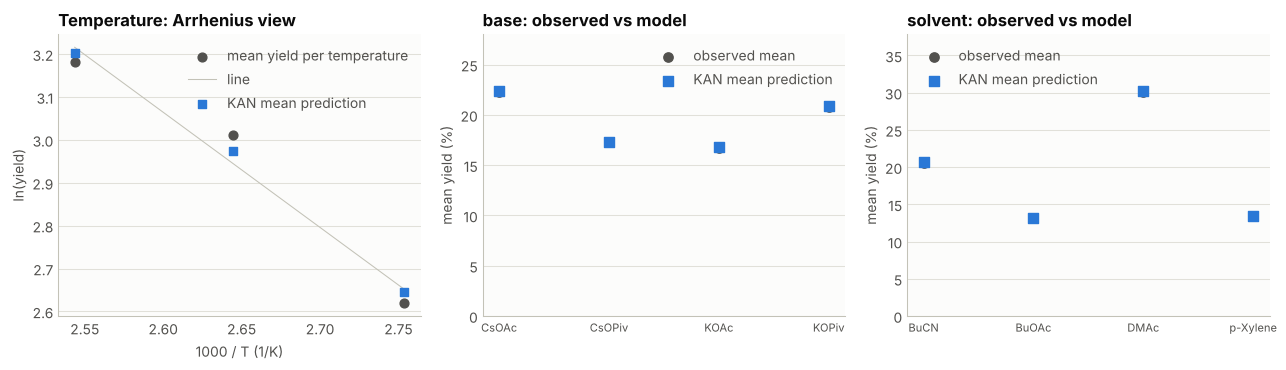

Mean yield by base and solvent (the CMD step involves the carboxylate):
solvent_file_name  BuCN  BuOAc  DMAc  p-Xylene
base_file_name                                
CsOAc              24.7   14.3  33.2      19.1
CsOPiv             21.6   11.4  23.9      11.7
KOAc               13.6   10.8  30.5       9.1
KOPiv              22.5   15.4  34.1      14.1

Mean yield by concentration and temperature:
Temp_C          90    105   120
Concentration                  
0.057          13.7  18.4  22.1
0.100          13.1  20.7  24.9
0.153          14.4  21.8  25.1


In [10]:
T = df["Temp_C"].to_numpy(dtype=float) + 273.15
gT = pd.DataFrame({"T": T, "yield": y}).groupby("T")["yield"].mean()
slope, intercept = np.polyfit(1.0 / gT.index.values, np.log(gT.values), 1)
print(f"Arrhenius-type fit of the three temperature means: ln(yield) = {intercept:.2f} {slope:+.0f}/T")
print(f"Apparent barrier from yields (not a measured activation energy): {-slope * 1.987e-3:.1f} kcal/mol")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
ax = axes[0]
style_axes(ax)
ax.scatter(1000.0 / gT.index.values, np.log(gT.values), s=40, color=INK_2, zorder=3, label="mean yield per temperature")
xx = np.linspace(1000.0 / T.max(), 1000.0 / T.min(), 50)
ax.plot(xx, intercept + slope * xx / 1000.0, color=BASELINE, linewidth=PX, label="line")
mT = model_means(df["Temp_C"])
ax.scatter(1000.0 / (mT.index.to_numpy() + 273.15), np.log(mT.predicted), s=40, marker="s", color=SERIES[0], zorder=4, label="KAN mean prediction")
ax.legend(frameon=False, fontsize=7)
finish_axes(ax, "Temperature: Arrhenius view", "1000 / T (1/K)", "ln(yield)")

for ax, name_col in zip(axes[1:], ["base_file_name", "solvent_file_name"]):
    style_axes(ax)
    mm = model_means(df[name_col])
    ax.scatter(np.arange(len(mm)), mm.observed, s=45, color=INK_2, zorder=3, label="observed mean")
    ax.scatter(np.arange(len(mm)), mm.predicted, s=45, marker="s", color=SERIES[0], zorder=4, label="KAN mean prediction")
    ax.set_xticks(np.arange(len(mm)))
    ax.set_xticklabels(mm.index, fontsize=8)
    ax.set_ylim(0, max(mm.observed.max(), mm.predicted.max()) * 1.25)
    ax.legend(frameon=False, fontsize=7)
    finish_axes(ax, f"{name_col.split('_')[0]}: observed vs model", "", "mean yield (%)")
plt.tight_layout()
plt.show()

print("Mean yield by base and solvent (the CMD step involves the carboxylate):")
print(df.pivot_table(index="base_file_name", columns="solvent_file_name", values="yield", aggfunc="mean").round(1))
print("\nMean yield by concentration and temperature:")
print(df.pivot_table(index="Concentration", columns="Temp_C", values="yield", aggfunc="mean").round(1))


### Reading

The conditions behave as a rate law says they should. The ligand descriptors do not resolve.

**Temperature.** Mean yield rises 13.7, 20.3, 24.1 % over 90, 105 and 120 degrees, and a straight
line through ln(yield) against 1/T gives an apparent barrier near 5 kcal/mol. The KAN reproduces
the three level means to within half a point. This is an apparent barrier from fixed-time yields,
not a measured activation energy, and three temperatures can support a slope and nothing more.

**Concentration.** 18.1, 19.6, 20.5 % over a factor of 2.7 in concentration: nearly flat. In a
catalytic cycle whose turnover-limiting step involves the catalyst and one substrate, raising both
partners together moves the yield little, which is what the data show.

**Solvent and base.** DMAc gives 30.4 % mean yield against 13.0 % for butyl acetate, and the
cesium and potassium pivalates beat the acetates in three of four solvents. The carboxylate sits
in the concerted metalation-deprotonation transition state, so this ordering is mechanistically
meaningful, but with four bases and four solvents it is an ordering of names. The level table
shows each of the four base descriptors reproducing the same four group means, which is the
signature of a component with fewer levels than descriptors.

**Ligands.** The spread is the largest effect in the dataset: 52.8 % for X-Phos and 50.2 % for
CgMe-PPh against 0.3 % for PPhMe2. The single best cut is on the percent buried volume at
phosphorus (balanced accuracy 0.690 at 83 %), another steric threshold. None of the six ligand
descriptor curves survives refitting: every envelope is comparable to or wider than the curve.
Twelve ligands is too few to attribute an effect to one of six correlated descriptors.

**Models.** Gradient boosting reaches cross-validated R2 0.894, the random forest 0.868, the KAN
0.865 and the linear model 0.289. The KAN loses to gradient boosting in 15 folds of 15, by 0.029.


## 6. Summary dashboard

Four tiles, all from the numbers above: cross-validated score per model, the best single cuts,
the sensitivity grouped by reaction component, and the stability of the top response curves.


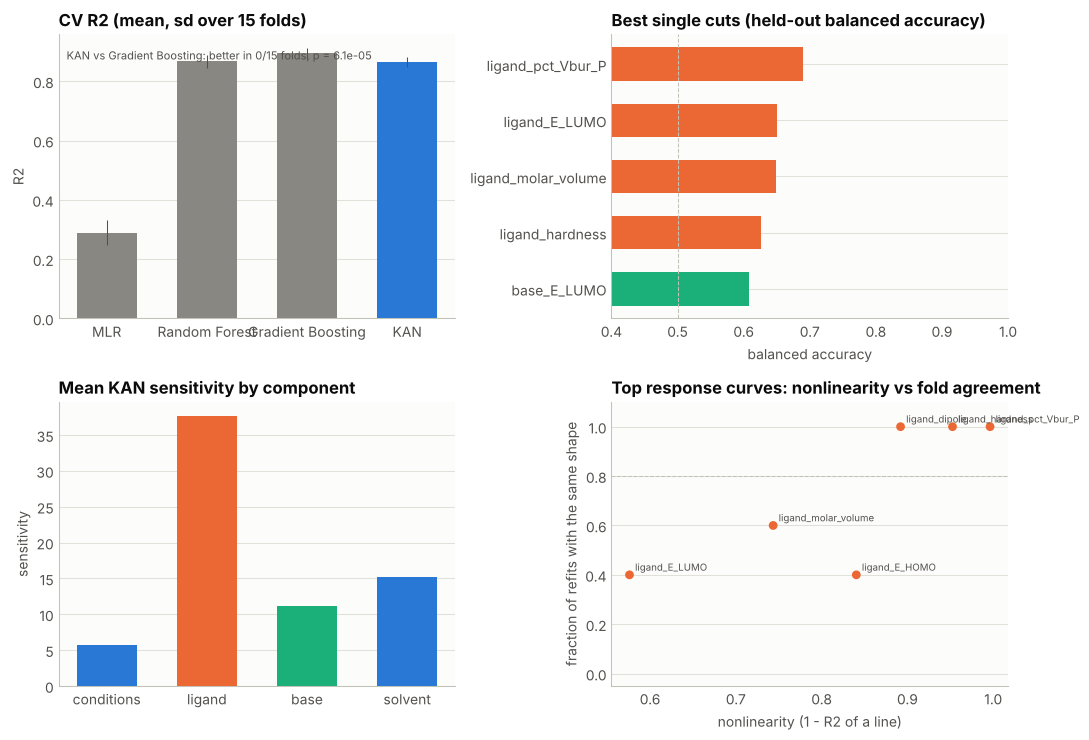

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
ax = axes[0, 0]
style_axes(ax)
s = cv_result.summary
names = list(s.index)
ax.bar(names, s[cv_result.metric + "_mean"], yerr=s[cv_result.metric + "_std"], color=[MUTED] * (len(names) - 1) + [SERIES[0]], width=0.6, linewidth=0, error_kw={"elinewidth": PX, "ecolor": INK_2})
p = cv_result.pairwise
finish_axes(ax, f"CV {cv_result.metric.upper()} (mean, sd over {CV_SPLITS * CV_REPEATS} folds)", "", cv_result.metric.upper())
ax.text(0.02, 0.95, f"KAN vs {p['vs']}: better in {p['wins']}/{p['n']} folds, p = {p['p']:.2g}", transform=ax.transAxes, va="top", fontsize=8, color=INK_2)

ax = axes[0, 1]
style_axes(ax)
top5 = rules.head(5).iloc[::-1]
ax.barh(top5.Feature, top5.Balanced_Acc, color=[COMP_COLOR[COMPONENT[f]] for f in top5.Feature], height=0.6, linewidth=0)
ax.axvline(0.5, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_xlim(0.4, 1.0)
finish_axes(ax, "Best single cuts (held-out balanced accuracy)", "balanced accuracy", "")

ax = axes[1, 0]
style_axes(ax)
comp_sens = sens_df.groupby("Component")["Sensitivity"].mean().reindex(COMPONENTS)
ax.bar(comp_sens.index, comp_sens.values, color=[COMP_COLOR[c] for c in comp_sens.index], width=0.6, linewidth=0)
finish_axes(ax, "Mean KAN sensitivity by component", "", "sensitivity")

ax = axes[1, 1]
style_axes(ax)
ax.scatter(stab["Nonlinearity"], stab["Fold agreement"], s=40, color=[COMP_COLOR[c] for c in stab.Component], linewidths=0, zorder=3)
for _, r in stab.iterrows():
    ax.annotate(r.Feature, (r.Nonlinearity, r["Fold agreement"]), fontsize=7, color=INK_2, xytext=(4, 3), textcoords="offset points")
ax.axhline(0.8, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_ylim(-0.05, 1.1)
finish_axes(ax, "Top response curves: nonlinearity vs fold agreement", "nonlinearity (1 - R2 of a line)", "fraction of refits with the same shape")
plt.tight_layout()
plt.show()
